In [1]:
import torch
import cv2
import json
import random
import time
import copy
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import ConcatDataset, Dataset, DataLoader
from torchvision.models import ResNet18_Weights, EfficientNet_B0_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

os.makedirs("outputs", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

BATCH_SIZE = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [3]:
NUM_CLASSES = 10
IMAGE_SIZE = 224

MAX_EPOCHS = 20
PATIENCE = 4

WEIGHT_DECAY = 1e-2

LR_SCRATCH = 1e-3
LR_CLASSIFIER = 1e-3
LR_LAYER4 = 1e-4

In [4]:
# Download both official portions before creating our internal split.
dataset_trainval = datasets.OxfordIIITPet(
    root="/content/data",
    split="trainval",
    target_types="category",
    download=True
)

dataset_official_test = datasets.OxfordIIITPet(
    root="/content/data",
    split="test",
    target_types="category",
    download=True
)

# Combine images while retaining the original class labels.
dataset_raw = ConcatDataset([
    dataset_trainval,
    dataset_official_test
])

# Obtain labels for both portions.
labels_trainval = list(dataset_trainval._labels)
labels_official_test = list(dataset_official_test._labels)

original_labels = np.array(
    labels_trainval + labels_official_test
)

original_classes = dataset_trainval.classes

print("Total images:", len(dataset_raw))
print("Total classes:", len(original_classes))
print("Class names:")
print(original_classes)

100%|██████████| 792M/792M [00:35<00:00, 22.1MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.8MB/s]


Total images: 7349
Total classes: 37
Class names:
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


In [5]:
def normalize_class_name(name):
    return name.lower().replace(" ", "_")


selected_classes = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "British Shorthair",
    "American Bulldog",
    "American Pit Bull Terrier",
    "Basset Hound",
    "Beagle",
    "Boxer"
]

normalized_to_original_id = {
    normalize_class_name(name): idx
    for idx, name in enumerate(original_classes)
}

missing_classes = [
    name for name in selected_classes
    if normalize_class_name(name) not in normalized_to_original_id
]

if missing_classes:
    raise ValueError(
        "These classes were not found: "
        + ", ".join(missing_classes)
        + "\nInspect original_classes in Cell 5."
    )

selected_original_ids = [
    normalized_to_original_id[normalize_class_name(name)]
    for name in selected_classes
]

# Map original class IDs to labels 0 through 9.
original_to_new_label = {
    original_id: new_id
    for new_id, original_id in enumerate(selected_original_ids)
}

# Keep only images belonging to the selected classes.
selected_indices = np.array([
    idx
    for idx, label in enumerate(original_labels)
    if label in original_to_new_label
])

selected_labels = np.array([
    original_to_new_label[original_labels[idx]]
    for idx in selected_indices
])

# Display names in the same order as the new numeric labels.
class_names = selected_classes

print("Selected classes:", class_names)
print("Number of selected images:", len(selected_indices))

print("\nImages per class:")
for class_id, class_name in enumerate(class_names):
    count = int(np.sum(selected_labels == class_id))
    print(f"{class_name}: {count}")

Selected classes: ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Boxer']
Number of selected images: 1981

Images per class:
Abyssinian: 198
Bengal: 200
Birman: 200
Bombay: 184
British Shorthair: 200
American Bulldog: 200
American Pit Bull Terrier: 200
Basset Hound: 200
Beagle: 200
Boxer: 199


In [6]:
train_indices, temp_indices, y_train, y_temp = train_test_split(
    selected_indices,
    selected_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=selected_labels
)

val_indices, test_indices, y_val, y_test = train_test_split(
    temp_indices,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))

total = (
    len(train_indices)
    + len(val_indices)
    + len(test_indices)
)

print(f"Train proportion: {len(train_indices) / total:.1%}")
print(f"Validation proportion: {len(val_indices) / total:.1%}")
print(f"Test proportion: {len(test_indices) / total:.1%}")

Train: 1386
Validation: 297
Test: 298
Train proportion: 70.0%
Validation proportion: 15.0%
Test proportion: 15.0%


In [7]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Used only for the training split when augmentation is enabled.
train_transform_augmented = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

# Used for validation, test, and B4 without augmentation.
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

print("Transforms are ready.")

Transforms are ready.


In [8]:
class PetSubsetDataset(Dataset):
    def __init__(
        self,
        root_dataset,
        indices,
        original_to_new_label,
        transform=None
    ):
        self.root_dataset = root_dataset
        self.indices = list(indices)
        self.original_to_new_label = original_to_new_label
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        original_index = self.indices[position]

        image, original_label = self.root_dataset[original_index]

        # Convert the original label to the selected 10-class label.
        label = self.original_to_new_label[int(original_label)]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loaders(use_augmentation=True):
    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_transform = (
        train_transform_augmented
        if use_augmentation
        else eval_transform
    )

    train_dataset = PetSubsetDataset(
        dataset_raw,
        train_indices,
        original_to_new_label,
        transform=train_transform
    )

    val_dataset = PetSubsetDataset(
        dataset_raw,
        val_indices,
        original_to_new_label,
        transform=eval_transform
    )

    test_dataset = PetSubsetDataset(
        dataset_raw,
        test_indices,
        original_to_new_label,
        transform=eval_transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
        worker_init_fn=seed_worker,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    return train_loader, val_loader, test_loader


train_loader, val_loader, test_loader = make_loaders(
    use_augmentation=True
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in batch:", labels[:10].tolist())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in batch: [5, 0, 0, 4, 8, 6, 4, 9, 0, 1]


In [9]:
def build_model(experiment):
    if experiment == "B1":
        model = models.resnet18(weights=None)
    elif experiment in [
        "B2", "B3",
        "B4_no_augmentation",
        "B4_with_augmentation"
    ]:
        model = models.resnet18(
            weights=ResNet18_Weights.IMAGENET1K_V1
        )
    else:
        raise ValueError(f"Unknown experiment: {experiment}")

    # Replace the original 1000-class ImageNet head.
    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    if experiment == "B1":
        # Train every layer from random initialization.
        for param in model.parameters():
            param.requires_grad = True

    elif experiment == "B2":
        # Freeze the backbone.
        for param in model.parameters():
            param.requires_grad = False

        # Train only the new classifier.
        for param in model.fc.parameters():
            param.requires_grad = True

    else:
        # B3 and B4: fine-tune layer4 and the classifier.
        for param in model.parameters():
            param.requires_grad = False

        for param in model.layer4.parameters():
            param.requires_grad = True

        for param in model.fc.parameters():
            param.requires_grad = True

    model = model.to(device)

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print(f"Experiment: {experiment}")
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")

    return model

In [10]:
def build_optimizer(model, experiment):
    if experiment == "B1":
        return optim.AdamW(
            filter(
                lambda p: p.requires_grad,
                model.parameters()
            ),
            lr=LR_SCRATCH,
            weight_decay=WEIGHT_DECAY
        )

    if experiment == "B2":
        return optim.AdamW(
            model.fc.parameters(),
            lr=LR_CLASSIFIER,
            weight_decay=WEIGHT_DECAY
        )

    if experiment == "B3" or experiment.startswith("B4"):
        return optim.AdamW(
            [
                {
                    "params": model.layer4.parameters(),
                    "lr": LR_LAYER4
                },
                {
                    "params": model.fc.parameters(),
                    "lr": LR_CLASSIFIER
                }
            ],
            weight_decay=WEIGHT_DECAY
        )

    raise ValueError(f"Unknown experiment: {experiment}")

In [11]:
def set_training_mode(model, experiment):
    model.train()

    if experiment == "B2":
        model.eval()
        model.fc.train()

    elif experiment == "B3" or experiment.startswith("B4"):
        # Keep the frozen backbone layers in evaluation mode.
        model.conv1.eval()
        model.bn1.eval()
        model.layer1.eval()
        model.layer2.eval()
        model.layer3.eval()


def run_epoch(
    model,
    loader,
    criterion,
    experiment,
    optimizer=None
):
    is_training = optimizer is not None

    if is_training:
        set_training_mode(model, experiment)
    else:
        model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

    average_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "labels": all_labels,
        "predictions": all_predictions
    }

In [12]:
def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    experiment,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE
):
    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    epochs_without_improvement = 0

    history = []
    start_time = time.time()

    for epoch in range(max_epochs):
        train_metrics = run_epoch(
            model,
            train_loader,
            criterion,
            experiment,
            optimizer=optimizer
        )

        val_metrics = run_epoch(
            model,
            val_loader,
            criterion,
            experiment,
            optimizer=None
        )

        history.append({
            "experiment": experiment,
            "epoch": epoch + 1,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"]
        })

        print(
            f"{experiment} | "
            f"Epoch {epoch + 1}/{max_epochs} | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Val Macro F1: {val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break

    training_duration = time.time() - start_time

    model.load_state_dict(best_state)

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        f"outputs/{experiment}_history.csv",
        index=False
    )

    torch.save(
        model.state_dict(),
        f"checkpoints/{experiment}_best.pth"
    )

    best_row = history_df.loc[
        history_df["epoch"] == best_epoch
    ].iloc[0]

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    if experiment == "B1":
        learning_rate_description = (
        f"all parameters: {LR_SCRATCH}"
    )

    elif experiment == "B2":
        learning_rate_description = (
        f"classifier: {LR_CLASSIFIER}"
    )

    elif experiment == "B5":
        learning_rate_description = (
        f"EfficientNet classifier: {LR_CLASSIFIER}"
    )

    else:
        # B3, B4_no_augmentation, B4_with_augmentation
        learning_rate_description = (
            f"layer4: {LR_LAYER4}; "
            f"classifier: {LR_CLASSIFIER}"
        )

    summary = {
        "experiment": experiment,
        "trainable_parameters": trainable_params,
        "learning_rates": learning_rate_description,
        "epochs_completed": len(history_df),
        "best_epoch": best_epoch,
        "best_val_loss": float(best_val_loss),
        "best_val_accuracy": float(
            best_row["val_accuracy"]
        ),
        "best_val_macro_f1": float(
            best_row["val_macro_f1"]
        ),
        "training_duration_seconds": training_duration
    }

    return model, history_df, summary

In [13]:
models_trained = {}
histories = {}
summaries = []

print("Experiment storage initialized.")

Experiment storage initialized.


# **BAGIAN 2**

**B1**

In [14]:
def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)


reset_seed()

train_loader, val_loader, test_loader = make_loaders(
    use_augmentation=True
)

model_b1 = build_model("B1")
optimizer_b1 = build_optimizer(model_b1, "B1")

model_b1, history_b1, summary_b1 = train_model(
    model_b1,
    train_loader,
    val_loader,
    optimizer_b1,
    experiment="B1"
)

models_trained["B1"] = model_b1
histories["B1"] = history_b1
summaries.append(summary_b1)

summary_b1

Experiment: B1
Total parameters: 11,181,642
Trainable parameters: 11,181,642
B1 | Epoch 1/20 | Train Loss: 2.3519 | Val Loss: 3.1301 | Val Acc: 0.2155 | Val Macro F1: 0.1185
B1 | Epoch 2/20 | Train Loss: 2.0862 | Val Loss: 2.0793 | Val Acc: 0.2694 | Val Macro F1: 0.2252
B1 | Epoch 3/20 | Train Loss: 1.9405 | Val Loss: 3.0524 | Val Acc: 0.2088 | Val Macro F1: 0.1812
B1 | Epoch 4/20 | Train Loss: 1.8408 | Val Loss: 1.9042 | Val Acc: 0.3367 | Val Macro F1: 0.2911
B1 | Epoch 5/20 | Train Loss: 1.7344 | Val Loss: 1.9536 | Val Acc: 0.3737 | Val Macro F1: 0.3315
B1 | Epoch 6/20 | Train Loss: 1.7038 | Val Loss: 1.8476 | Val Acc: 0.3603 | Val Macro F1: 0.3433
B1 | Epoch 7/20 | Train Loss: 1.6541 | Val Loss: 1.6783 | Val Acc: 0.4175 | Val Macro F1: 0.3892
B1 | Epoch 8/20 | Train Loss: 1.5561 | Val Loss: 1.6577 | Val Acc: 0.4646 | Val Macro F1: 0.4097
B1 | Epoch 9/20 | Train Loss: 1.4978 | Val Loss: 1.8567 | Val Acc: 0.3973 | Val Macro F1: 0.3934
B1 | Epoch 10/20 | Train Loss: 1.4783 | Val Loss: 

{'experiment': 'B1',
 'trainable_parameters': 11181642,
 'learning_rates': 'all parameters: 0.001',
 'epochs_completed': 20,
 'best_epoch': 20,
 'best_val_loss': 1.2526005157316573,
 'best_val_accuracy': 0.5757575757575758,
 'best_val_macro_f1': 0.5645359685082963,
 'training_duration_seconds': 343.5272870063782}

**B2**

In [15]:
reset_seed()

train_loader, val_loader, test_loader = make_loaders(
    use_augmentation=True
)

model_b2 = build_model("B2")
optimizer_b2 = build_optimizer(model_b2, "B2")

model_b2, history_b2, summary_b2 = train_model(
    model_b2,
    train_loader,
    val_loader,
    optimizer_b2,
    experiment="B2"
)

models_trained["B2"] = model_b2
histories["B2"] = history_b2
summaries.append(summary_b2)

summary_b2

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 125MB/s]


Experiment: B2
Total parameters: 11,181,642
Trainable parameters: 5,130
B2 | Epoch 1/20 | Train Loss: 1.3945 | Val Loss: 0.7201 | Val Acc: 0.8519 | Val Macro F1: 0.8486
B2 | Epoch 2/20 | Train Loss: 0.5857 | Val Loss: 0.4207 | Val Acc: 0.9158 | Val Macro F1: 0.9162
B2 | Epoch 3/20 | Train Loss: 0.4230 | Val Loss: 0.3695 | Val Acc: 0.9125 | Val Macro F1: 0.9129
B2 | Epoch 4/20 | Train Loss: 0.3300 | Val Loss: 0.2898 | Val Acc: 0.9394 | Val Macro F1: 0.9395
B2 | Epoch 5/20 | Train Loss: 0.2979 | Val Loss: 0.2983 | Val Acc: 0.9226 | Val Macro F1: 0.9232
B2 | Epoch 6/20 | Train Loss: 0.2637 | Val Loss: 0.2682 | Val Acc: 0.9293 | Val Macro F1: 0.9296
B2 | Epoch 7/20 | Train Loss: 0.2502 | Val Loss: 0.2710 | Val Acc: 0.9327 | Val Macro F1: 0.9333
B2 | Epoch 8/20 | Train Loss: 0.2278 | Val Loss: 0.2403 | Val Acc: 0.9461 | Val Macro F1: 0.9463
B2 | Epoch 9/20 | Train Loss: 0.2137 | Val Loss: 0.2295 | Val Acc: 0.9428 | Val Macro F1: 0.9430
B2 | Epoch 10/20 | Train Loss: 0.1932 | Val Loss: 0.233

{'experiment': 'B2',
 'trainable_parameters': 5130,
 'learning_rates': 'classifier: 0.001',
 'epochs_completed': 17,
 'best_epoch': 13,
 'best_val_loss': 0.22346606170789962,
 'best_val_accuracy': 0.9292929292929293,
 'best_val_macro_f1': 0.9294522118383716,
 'training_duration_seconds': 229.9397964477539}

**B3**

In [16]:
reset_seed()

train_loader, val_loader, test_loader = make_loaders(
    use_augmentation=True
)

model_b3 = build_model("B3")
optimizer_b3 = build_optimizer(model_b3, "B3")

model_b3, history_b3, summary_b3 = train_model(
    model_b3,
    train_loader,
    val_loader,
    optimizer_b3,
    experiment="B3"
)

models_trained["B3"] = model_b3
histories["B3"] = history_b3
summaries.append(summary_b3)

summary_b3

Experiment: B3
Total parameters: 11,181,642
Trainable parameters: 8,398,858
B3 | Epoch 1/20 | Train Loss: 0.8033 | Val Loss: 0.2325 | Val Acc: 0.9360 | Val Macro F1: 0.9368
B3 | Epoch 2/20 | Train Loss: 0.2092 | Val Loss: 0.2232 | Val Acc: 0.9293 | Val Macro F1: 0.9306
B3 | Epoch 3/20 | Train Loss: 0.1470 | Val Loss: 0.1973 | Val Acc: 0.9428 | Val Macro F1: 0.9439
B3 | Epoch 4/20 | Train Loss: 0.0926 | Val Loss: 0.1940 | Val Acc: 0.9495 | Val Macro F1: 0.9499
B3 | Epoch 5/20 | Train Loss: 0.0600 | Val Loss: 0.2237 | Val Acc: 0.9327 | Val Macro F1: 0.9332
B3 | Epoch 6/20 | Train Loss: 0.0517 | Val Loss: 0.2254 | Val Acc: 0.9428 | Val Macro F1: 0.9434
B3 | Epoch 7/20 | Train Loss: 0.0349 | Val Loss: 0.1856 | Val Acc: 0.9630 | Val Macro F1: 0.9633
B3 | Epoch 8/20 | Train Loss: 0.0328 | Val Loss: 0.2317 | Val Acc: 0.9360 | Val Macro F1: 0.9366
B3 | Epoch 9/20 | Train Loss: 0.0197 | Val Loss: 0.2228 | Val Acc: 0.9428 | Val Macro F1: 0.9431
B3 | Epoch 10/20 | Train Loss: 0.0150 | Val Loss: 0

{'experiment': 'B3',
 'trainable_parameters': 8398858,
 'learning_rates': 'layer4: 0.0001; classifier: 0.001',
 'epochs_completed': 11,
 'best_epoch': 7,
 'best_val_loss': 0.18556270477446643,
 'best_val_accuracy': 0.9629629629629629,
 'best_val_macro_f1': 0.9632734743890022,
 'training_duration_seconds': 148.03466701507568}

**B4**

In [17]:
b4_configs = {
    "B4_no_augmentation": False,
    "B4_with_augmentation": True
}

b4_summaries = []

for experiment_name, use_augmentation in b4_configs.items():
    print("\n" + "=" * 60)
    print("Running:", experiment_name)
    print("=" * 60)

    reset_seed()

    train_loader, val_loader, test_loader = make_loaders(
        use_augmentation=use_augmentation
    )

    model = build_model(experiment_name)
    optimizer = build_optimizer(model, experiment_name)

    model, history_df, summary = train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        experiment=experiment_name
    )

    models_trained[experiment_name] = model
    histories[experiment_name] = history_df
    b4_summaries.append(summary)

summaries.extend(b4_summaries)

pd.DataFrame(b4_summaries)


Running: B4_no_augmentation
Experiment: B4_no_augmentation
Total parameters: 11,181,642
Trainable parameters: 8,398,858
B4_no_augmentation | Epoch 1/20 | Train Loss: 0.7316 | Val Loss: 0.2190 | Val Acc: 0.9394 | Val Macro F1: 0.9398
B4_no_augmentation | Epoch 2/20 | Train Loss: 0.1048 | Val Loss: 0.2140 | Val Acc: 0.9394 | Val Macro F1: 0.9399
B4_no_augmentation | Epoch 3/20 | Train Loss: 0.0377 | Val Loss: 0.1863 | Val Acc: 0.9428 | Val Macro F1: 0.9434
B4_no_augmentation | Epoch 4/20 | Train Loss: 0.0208 | Val Loss: 0.1840 | Val Acc: 0.9495 | Val Macro F1: 0.9499
B4_no_augmentation | Epoch 5/20 | Train Loss: 0.0091 | Val Loss: 0.2038 | Val Acc: 0.9495 | Val Macro F1: 0.9496
B4_no_augmentation | Epoch 6/20 | Train Loss: 0.0064 | Val Loss: 0.1983 | Val Acc: 0.9428 | Val Macro F1: 0.9433
B4_no_augmentation | Epoch 7/20 | Train Loss: 0.0043 | Val Loss: 0.1862 | Val Acc: 0.9529 | Val Macro F1: 0.9531
B4_no_augmentation | Epoch 8/20 | Train Loss: 0.0031 | Val Loss: 0.1884 | Val Acc: 0.949

,experiment,trainable_parameters,learning_rates,epochs_completed,best_epoch,best_val_loss,best_val_accuracy,best_val_macro_f1,training_duration_seconds
0,B4_no_augmentation,8398858,layer4: 0.0001; classifier: 0.001,8,4,0.183975,0.949495,0.949859,73.879200
1,B4_with_augmentation,8398858,layer4: 0.0001; classifier: 0.001,11,7,0.185563,0.962963,0.963273,149.954213


**B5**

In [18]:
def build_efficientnet_b0():
    model = models.efficientnet_b0(
        weights=EfficientNet_B0_Weights.IMAGENET1K_V1
    )

    # Freeze pretrained feature extractor.
    for param in model.parameters():
        param.requires_grad = False

    # Replace the final classifier.
    in_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        in_features,
        NUM_CLASSES
    )

    # Train only the new classifier.
    for param in model.classifier.parameters():
        param.requires_grad = True

    return model.to(device)

In [19]:
reset_seed()

train_loader, val_loader, test_loader = make_loaders(
    use_augmentation=True
)

model_b5 = build_efficientnet_b0()

optimizer_b5 = optim.AdamW(
    model_b5.classifier.parameters(),
    lr=LR_CLASSIFIER,
    weight_decay=WEIGHT_DECAY
)

model_b5, history_b5, summary_b5 = train_model(
    model_b5,
    train_loader,
    val_loader,
    optimizer_b5,
    experiment="B5"
)

models_trained["B5"] = model_b5
histories["B5"] = history_b5
summaries.append(summary_b5)

summary_b5

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 136MB/s]


B5 | Epoch 1/20 | Train Loss: 1.5461 | Val Loss: 0.9065 | Val Acc: 0.8653 | Val Macro F1: 0.8641
B5 | Epoch 2/20 | Train Loss: 0.7951 | Val Loss: 0.5837 | Val Acc: 0.9057 | Val Macro F1: 0.9047
B5 | Epoch 3/20 | Train Loss: 0.5959 | Val Loss: 0.4643 | Val Acc: 0.9091 | Val Macro F1: 0.9086
B5 | Epoch 4/20 | Train Loss: 0.5020 | Val Loss: 0.4092 | Val Acc: 0.9091 | Val Macro F1: 0.9078
B5 | Epoch 5/20 | Train Loss: 0.4341 | Val Loss: 0.3705 | Val Acc: 0.9057 | Val Macro F1: 0.9043
B5 | Epoch 6/20 | Train Loss: 0.3844 | Val Loss: 0.3431 | Val Acc: 0.9192 | Val Macro F1: 0.9189
B5 | Epoch 7/20 | Train Loss: 0.3658 | Val Loss: 0.3230 | Val Acc: 0.9158 | Val Macro F1: 0.9155
B5 | Epoch 8/20 | Train Loss: 0.3404 | Val Loss: 0.3109 | Val Acc: 0.9125 | Val Macro F1: 0.9115
B5 | Epoch 9/20 | Train Loss: 0.3303 | Val Loss: 0.2970 | Val Acc: 0.9158 | Val Macro F1: 0.9153
B5 | Epoch 10/20 | Train Loss: 0.2859 | Val Loss: 0.2925 | Val Acc: 0.9158 | Val Macro F1: 0.9151
B5 | Epoch 11/20 | Train Loss

{'experiment': 'B5',
 'trainable_parameters': 12810,
 'learning_rates': 'EfficientNet classifier: 0.001',
 'epochs_completed': 20,
 'best_epoch': 20,
 'best_val_loss': 0.23817249334821797,
 'best_val_accuracy': 0.9292929292929293,
 'best_val_macro_f1': 0.9291157674116391,
 'training_duration_seconds': 275.1291084289551}

# **BAGIAN 3**

In [20]:
summary_df = pd.DataFrame(summaries)

summary_df.to_csv(
    "outputs/experiment_summary.csv",
    index=False
)

summary_df

,experiment,trainable_parameters,learning_rates,epochs_completed,best_epoch,best_val_loss,best_val_accuracy,best_val_macro_f1,training_duration_seconds
0,B1,11181642,all parameters: 0.001,20,20,1.252601,0.575758,0.564536,343.527287
1,B2,5130,classifier: 0.001,17,13,0.223466,0.929293,0.929452,229.939796
2,B3,8398858,layer4: 0.0001; classifier: 0.001,11,7,0.185563,0.962963,0.963273,148.034667
3,B4_no_augmentation,8398858,layer4: 0.0001; classifier: 0.001,8,4,0.183975,0.949495,0.949859,73.879200
4,B4_with_augmentation,8398858,layer4: 0.0001; classifier: 0.001,11,7,0.185563,0.962963,0.963273,149.954213
5,B5,12810,EfficientNet classifier: 0.001,20,20,0.238172,0.929293,0.929116,275.129108


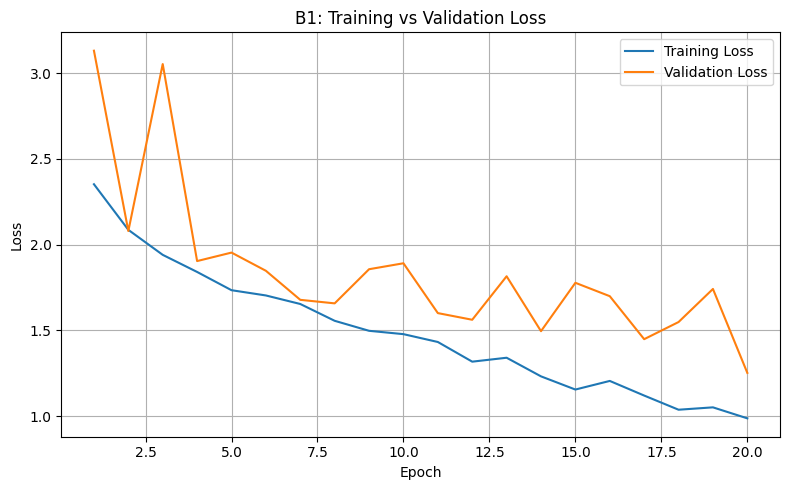

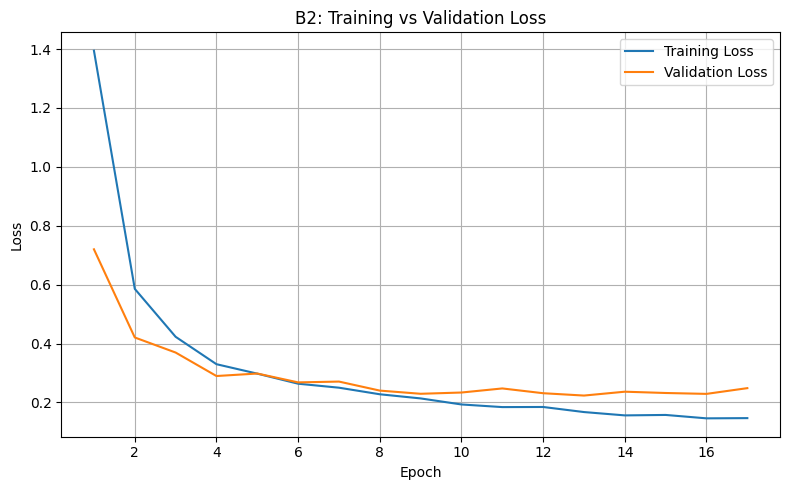

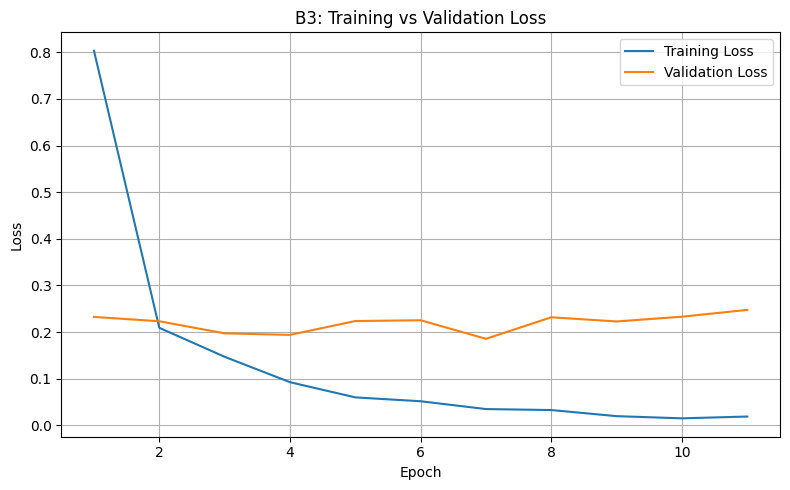

In [21]:
for experiment in ["B1", "B2", "B3"]:
    history_df = histories[experiment]

    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{experiment}: Training vs Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        f"outputs/{experiment}_loss_curve.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

In [22]:
comparison_rows = []

for experiment, history_df in histories.items():
    best_idx = history_df["val_loss"].idxmin()
    best_row = history_df.loc[best_idx]

    comparison_rows.append({
        "experiment": experiment,
        "best_epoch": int(best_row["epoch"]),
        "validation_accuracy": best_row["val_accuracy"],
        "validation_macro_f1": best_row["val_macro_f1"]
    })

validation_comparison_df = pd.DataFrame(comparison_rows)

validation_comparison_df.to_csv(
    "outputs/validation_comparison.csv",
    index=False
)

validation_comparison_df

,experiment,best_epoch,validation_accuracy,validation_macro_f1
0,B1,20,0.575758,0.564536
1,B2,13,0.929293,0.929452
2,B3,7,0.962963,0.963273
3,B4_no_augmentation,4,0.949495,0.949859
4,B4_with_augmentation,7,0.962963,0.963273
5,B5,20,0.929293,0.929116


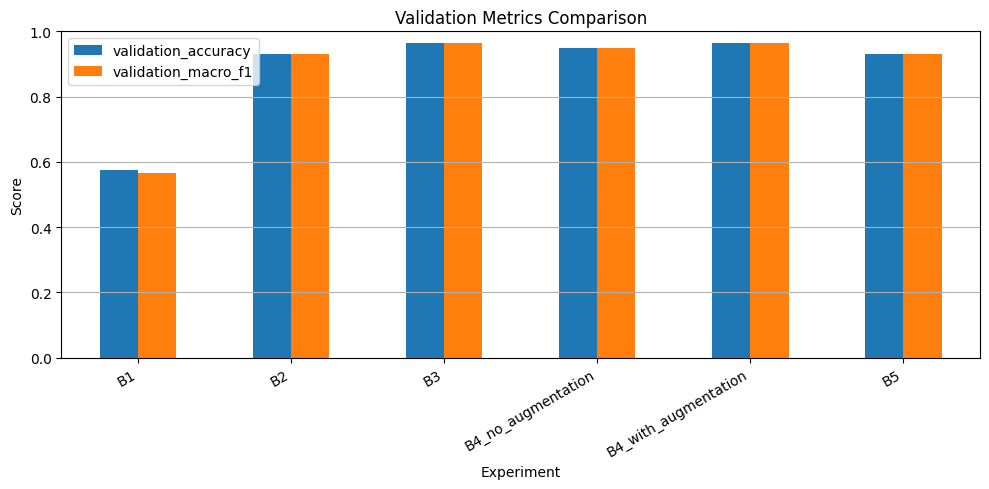

In [23]:
validation_comparison_df.set_index("experiment")[
    ["validation_accuracy", "validation_macro_f1"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Validation Metrics Comparison")
plt.xlabel("Experiment")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    "outputs/validation_metrics_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [24]:
b4_names = [
    "B4_no_augmentation",
    "B4_with_augmentation"
]

b4_comparison = validation_comparison_df[
    validation_comparison_df["experiment"].isin(b4_names)
].copy()

b4_comparison

,experiment,best_epoch,validation_accuracy,validation_macro_f1
3,B4_no_augmentation,4,0.949495,0.949859
4,B4_with_augmentation,7,0.962963,0.963273


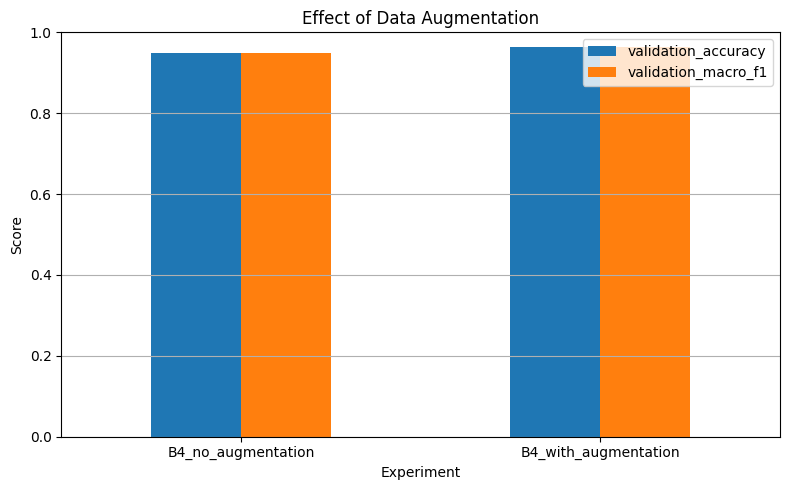

In [25]:
b4_comparison.set_index("experiment")[
    ["validation_accuracy", "validation_macro_f1"]
].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Effect of Data Augmentation")
plt.xlabel("Experiment")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    "outputs/B4_augmentation_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [26]:
eligible_experiments = [
    experiment
    for experiment in histories
    if experiment in models_trained
]

best_validation_rows = []

for experiment in eligible_experiments:
    history_df = histories[experiment]
    best_idx = history_df["val_loss"].idxmin()
    row = history_df.loc[best_idx]

    best_validation_rows.append({
        "experiment": experiment,
        "val_loss": row["val_loss"],
        "val_macro_f1": row["val_macro_f1"]
    })

best_validation_df = pd.DataFrame(best_validation_rows)

selected_experiment = best_validation_df.sort_values(
    by="val_macro_f1",
    ascending=False
).iloc[0]["experiment"]

print("Selected model:", selected_experiment)

Selected model: B4_with_augmentation


In [27]:
test_results = []
test_outputs = {}

# Use the same internal test split for every experiment.
_, _, test_loader = make_loaders(use_augmentation=False)

for experiment, model in models_trained.items():
    criterion = nn.CrossEntropyLoss()

    metrics = run_epoch(
        model=model,
        loader=test_loader,
        criterion=criterion,
        experiment=experiment,
        optimizer=None
    )

    test_outputs[experiment] = metrics

    test_results.append({
        "experiment": experiment,
        "test_loss": metrics["loss"],
        "test_accuracy": metrics["accuracy"],
        "test_macro_f1": metrics["macro_f1"]
    })

test_metrics_df = pd.DataFrame(test_results)

test_metrics_df.to_csv(
    "outputs/test_metrics.csv",
    index=False
)

test_metrics_df

,experiment,test_loss,test_accuracy,test_macro_f1
0,B1,1.447972,0.543624,0.526036
1,B2,0.222355,0.912752,0.913205
2,B3,0.202313,0.936242,0.936216
3,B4_no_augmentation,0.174591,0.932886,0.933086
4,B4_with_augmentation,0.202313,0.936242,0.936216
5,B5,0.248705,0.909396,0.909507


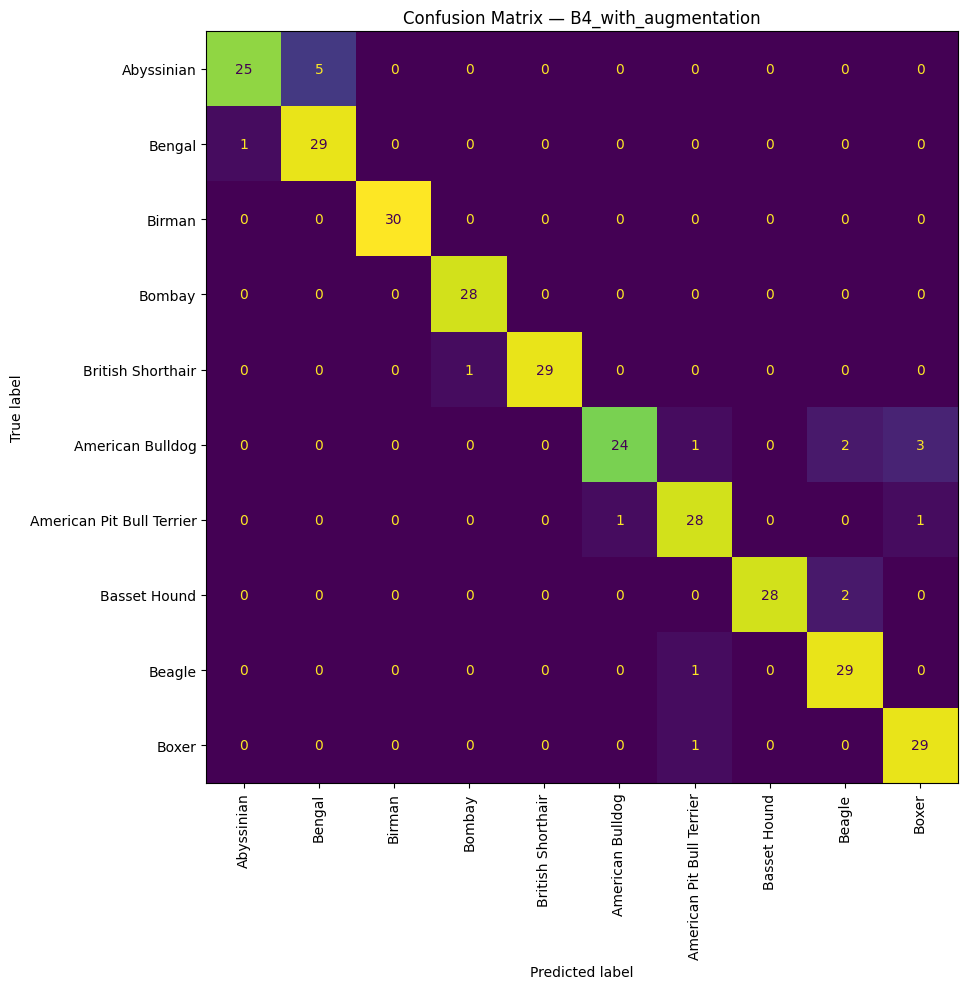

In [28]:
selected_metrics = test_outputs[selected_experiment]

cm = confusion_matrix(
    selected_metrics["labels"],
    selected_metrics["predictions"],
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False
)

plt.title(f"Confusion Matrix — {selected_experiment}")
plt.tight_layout()

plt.savefig(
    "outputs/confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

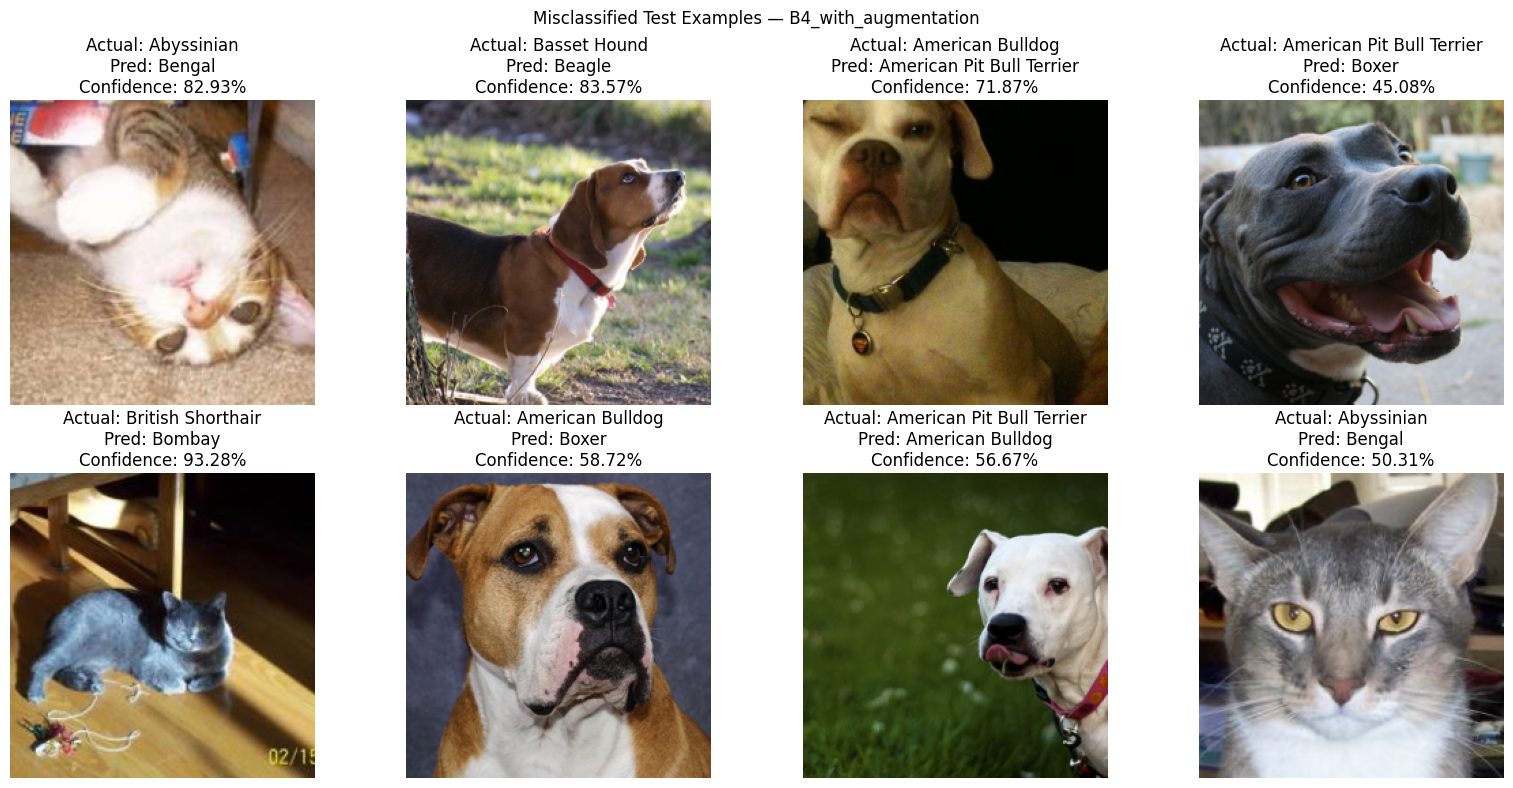

In [29]:
def show_misclassified_examples(
    model,
    experiment,
    max_examples=8
):
    _, _, test_loader = make_loaders(use_augmentation=False)

    model.eval()
    mistakes = []

    with torch.no_grad():
        for images, labels in test_loader:
            images_device = images.to(device)
            outputs = model(images_device)

            probabilities = torch.softmax(outputs, dim=1)
            confidences, predictions = probabilities.max(dim=1)

            for i in range(len(labels)):
                actual = int(labels[i])
                predicted = int(predictions[i].cpu())

                if actual != predicted:
                    mistakes.append({
                        "image": images[i].cpu(),
                        "actual": actual,
                        "predicted": predicted,
                        "confidence": float(
                            confidences[i].cpu()
                        )
                    })

                if len(mistakes) >= max_examples:
                    break

            if len(mistakes) >= max_examples:
                break

    if not mistakes:
        print("No misclassified examples found in this pass.")
        return

    mean = torch.tensor(imagenet_mean).view(3, 1, 1)
    std = torch.tensor(imagenet_std).view(3, 1, 1)

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(16, 8)
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, mistakes):
        image = item["image"] * std + mean
        image = image.clamp(0, 1).permute(1, 2, 0).numpy()

        ax.imshow(image)
        ax.set_title(
            f"Actual: {class_names[item['actual']]}\n"
            f"Pred: {class_names[item['predicted']]}\n"
            f"Confidence: {item['confidence']:.2%}"
        )
        ax.axis("off")

    plt.suptitle(
        f"Misclassified Test Examples — {experiment}"
    )
    plt.tight_layout()
    plt.show()

    return mistakes


misclassified_examples = show_misclassified_examples(
    models_trained[selected_experiment],
    selected_experiment,
    max_examples=8
)

In [30]:
selected_metrics = test_outputs[selected_experiment]

report = classification_report(
    selected_metrics["labels"],
    selected_metrics["predictions"],
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

classification_report_df = pd.DataFrame(report).transpose()

classification_report_df.to_csv(
    "outputs/classification_report.csv",
    index=True
)

classification_report_df

,precision,recall,f1-score,support
Abyssinian,0.961538,0.833333,0.892857,30.000000
Bengal,0.852941,0.966667,0.906250,30.000000
Birman,1.000000,1.000000,1.000000,30.000000
Bombay,0.965517,1.000000,0.982456,28.000000
British Shorthair,1.000000,0.966667,0.983051,30.000000
American Bulldog,0.960000,0.800000,0.872727,30.000000
American Pit Bull Terrier,0.903226,0.933333,0.918033,30.000000
Basset Hound,1.000000,0.933333,0.965517,30.000000
Beagle,0.878788,0.966667,0.920635,30.000000
Boxer,0.878788,0.966667,0.920635,30.000000


In [31]:
final_summary_df = pd.DataFrame(summaries)

final_summary_df = final_summary_df.merge(
    test_metrics_df[
        ["experiment", "test_accuracy", "test_macro_f1"]
    ],
    on="experiment",
    how="left"
)

final_summary_df.to_csv(
    "outputs/final_experiment_summary.csv",
    index=False
)

final_summary_df

,experiment,trainable_parameters,learning_rates,epochs_completed,best_epoch,best_val_loss,best_val_accuracy,best_val_macro_f1,training_duration_seconds,test_accuracy,test_macro_f1
0,B1,11181642,all parameters: 0.001,20,20,1.252601,0.575758,0.564536,343.527287,0.543624,0.526036
1,B2,5130,classifier: 0.001,17,13,0.223466,0.929293,0.929452,229.939796,0.912752,0.913205
2,B3,8398858,layer4: 0.0001; classifier: 0.001,11,7,0.185563,0.962963,0.963273,148.034667,0.936242,0.936216
3,B4_no_augmentation,8398858,layer4: 0.0001; classifier: 0.001,8,4,0.183975,0.949495,0.949859,73.879200,0.932886,0.933086
4,B4_with_augmentation,8398858,layer4: 0.0001; classifier: 0.001,11,7,0.185563,0.962963,0.963273,149.954213,0.936242,0.936216
5,B5,12810,EfficientNet classifier: 0.001,20,20,0.238172,0.929293,0.929116,275.129108,0.909396,0.909507


In [32]:
raw_metrics = {
    "configuration": {
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "image_size": IMAGE_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "weight_decay": WEIGHT_DECAY,
        "classes": class_names
    },
    "experiments": final_summary_df.to_dict(
        orient="records"
    ),
    "test_metrics": test_metrics_df.to_dict(
        orient="records"
    )
}

with open(
    "outputs/raw_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        raw_metrics,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Metrics exported successfully.")

Metrics exported successfully.


In [33]:
for root, dirs, files in os.walk("outputs"):
    for filename in sorted(files):
        print(os.path.join(root, filename))

print("\nSaved checkpoints:")
for filename in sorted(os.listdir("checkpoints")):
    print(os.path.join("checkpoints", filename))

outputs/B1_history.csv
outputs/B1_loss_curve.png
outputs/B2_history.csv
outputs/B2_loss_curve.png
outputs/B3_history.csv
outputs/B3_loss_curve.png
outputs/B4_augmentation_comparison.png
outputs/B4_no_augmentation_history.csv
outputs/B4_with_augmentation_history.csv
outputs/B5_history.csv
outputs/classification_report.csv
outputs/confusion_matrix.png
outputs/experiment_summary.csv
outputs/final_experiment_summary.csv
outputs/raw_metrics.json
outputs/test_metrics.csv
outputs/validation_comparison.csv
outputs/validation_metrics_comparison.png

Saved checkpoints:
checkpoints/B1_best.pth
checkpoints/B2_best.pth
checkpoints/B3_best.pth
checkpoints/B4_no_augmentation_best.pth
checkpoints/B4_with_augmentation_best.pth
checkpoints/B5_best.pth
